In [1]:
import os
import random
import re
import unicodedata
from collections import Counter

from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

print(f"Ustawione ziarno losowosci: {SEED}")

ds = load_dataset("cornell-movie-review-data/rotten_tomatoes")
ds

Ustawione ziarno losowosci: 42


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
})

# Część 1: Przygotowanie tekstu, słownik i DataLoader

### 1.1 Tokenizacja, normalizacja i budowa słownika

In [2]:
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
PAD_IDX = 0
UNK_IDX = 1

TOKEN_PATTERN = re.compile(r"[^\W_]+(?:'[^\W_]+)*")


def normalize_text(text):
    return unicodedata.normalize("NFKC", text).casefold()


def tokenize(text):
    return TOKEN_PATTERN.findall(normalize_text(text))


def build_vocabulary(training_texts):
    vocabulary = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}
    unique_tokens = sorted({token for text in training_texts for token in tokenize(text)})
    for token in unique_tokens:
        vocabulary[token] = len(vocabulary)
    return vocabulary

In [3]:
train_texts = ds["train"]["text"]
vocabulary = build_vocabulary(train_texts)
id_to_token = {idx: token for token, idx in vocabulary.items()}

print(f"Liczba tekstow treningowych: {len(train_texts)}")
print(f"Rozmiar slownika: {len(vocabulary)}")
print("Pierwsze 10 tokenow ze slownika:", [(idx, id_to_token[idx]) for idx in range(10)])

Liczba tekstow treningowych: 8530
Rozmiar slownika: 17105
Pierwsze 10 tokenow ze slownika: [(0, '<pad>'), (1, '<unk>'), (2, '00'), (3, '007'), (4, '1'), (5, '10'), (6, '100'), (7, '101'), (8, '102'), (9, '104')]


### 1.2 Kodowanie sekwencji, funkcja collate_fn i DataLoadery

In [4]:
class RottenTomatoesDataset(Dataset):
    def __init__(self, split_data, vocab):
        self.texts = split_data["text"]
        self.labels = split_data["label"]
        self.vocab = vocab

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        tokens = tokenize(self.texts[idx])
        token_ids = [self.vocab.get(token, UNK_IDX) for token in tokens]
        if not token_ids:
            token_ids = [UNK_IDX]
        return torch.tensor(token_ids, dtype=torch.long), self.labels[idx]


def collate_fn(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    padded_sequences = torch.nn.utils.rnn.pad_sequence(
        sequences,
        batch_first=True,
        padding_value=PAD_IDX,
    )
    labels_tensor = torch.tensor(labels, dtype=torch.long)
    return padded_sequences, lengths, labels_tensor


train_dataset = RottenTomatoesDataset(ds["train"], vocabulary)
val_dataset = RottenTomatoesDataset(ds["validation"], vocabulary)
test_dataset = RottenTomatoesDataset(ds["test"], vocabulary)

BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

print(f"Liczba batchy w train: {len(train_loader)}")
print(f"Liczba batchy w validation: {len(val_loader)}")
print(f"Liczba batchy w test: {len(test_loader)}")

Liczba batchy w train: 134
Liczba batchy w validation: 17
Liczba batchy w test: 17


In [5]:
sample_inputs, sample_lengths, sample_labels = next(iter(train_loader))
print(f"Ksztalt batcha wejsciowego (inputs): {sample_inputs.shape}")
print(f"Ksztalt wektora dlugosci (lengths): {sample_lengths.shape}")
print(f"Ksztalt etykiet (labels): {sample_labels.shape}")
print(f"Pierwsza sekwencja w batchu (token IDs):\n{sample_inputs[0][:15].tolist()}...")
print(f"Dlugosc pierwszej sekwencji: {sample_lengths[0].item()}")
print(f"Etykieta pierwszej sekwencji: {sample_labels[0].item()}")

Ksztalt batcha wejsciowego (inputs): torch.Size([64, 37])
Ksztalt wektora dlugosci (lengths): torch.Size([64])
Ksztalt etykiet (labels): torch.Size([64])
Pierwsza sekwencja w batchu (token IDs):
[16587, 6370, 14003, 15671, 16014, 2463, 14562, 702, 174, 3504, 13238, 10406, 646, 15183, 7194]...
Dlugosc pierwszej sekwencji: 21
Etykieta pierwszej sekwencji: 1


# Część 2: Definicja i inicjalizacja modelu RNN

### 2.1 Architektura klasyfikatora RNN

In [6]:
class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_classes=2,
        num_layers=1,
        bidirectional=False,
        dropout=0.5,
        pad_idx=0,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            bidirectional=bidirectional,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        rnn_output_dim = hidden_dim * 2 if bidirectional else hidden_dim
        self.classifier = nn.Linear(rnn_output_dim, num_classes)

    def forward(self, text, lengths):
        embedded = self.embedding(text)
        packed_embedded = torch.nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        _, hidden = self.rnn(packed_embedded)
        if self.rnn.bidirectional:
            h = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            h = hidden[-1]
        h = self.dropout(h)
        return self.classifier(h)

### 2.2 Inicjalizacja modelu, liczba parametrów i test przejścia w przód

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"Urzadzenie: {device}")

EMBEDDING_DIM = 128
HIDDEN_DIM = 128
NUM_CLASSES = 2
NUM_LAYERS = 1
BIDIRECTIONAL = False
DROPOUT = 0.5

model = RNNClassifier(
    vocab_size=len(vocabulary),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    dropout=DROPOUT,
    pad_idx=PAD_IDX,
).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print(f"Liczba wszystkich parametrow: {total_params}")
print(f"Liczba uczonych parametrow: {trainable_params}")

model.eval()
with torch.no_grad():
    batch_inputs = sample_inputs.to(device)
    batch_lengths = sample_lengths
    sample_logits = model(batch_inputs, batch_lengths)
    sample_probs = torch.softmax(sample_logits, dim=-1)

print(f"Ksztalt logitow wyjsciowych: {sample_logits.shape}")
print(f"Przykladowe logity dla pierwszej recenzji: {sample_logits[0].tolist()}")
print(f"Przykladowe prawdopodobienstwa klas (softmax): {sample_probs[0].tolist()}")

Urzadzenie: mps
RNNClassifier(
  (embedding): Embedding(17105, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)
Liczba wszystkich parametrow: 2222722
Liczba uczonych parametrow: 2222722
Ksztalt logitow wyjsciowych: torch.Size([64, 2])
Przykladowe logity dla pierwszej recenzji: [0.02350391075015068, 0.5009207129478455]
Przykladowe prawdopodobienstwa klas (softmax): [0.38286229968070984, 0.6171377301216125]


# Część 3: Pętla treningowa, ewaluacja i zapisywanie checkpointów

### 3.1 Funkcje trenujące i ewaluacyjne

In [8]:
def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for inputs, lengths, labels in dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = model(inputs, lengths)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        predictions = logits.argmax(dim=-1)
        correct += (predictions == labels).sum().item()
        total += len(labels)
    return total_loss / total, correct / total


def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, lengths, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            logits = model(inputs, lengths)
            loss = criterion(logits, labels)
            total_loss += loss.item() * len(labels)
            predictions = logits.argmax(dim=-1)
            correct += (predictions == labels).sum().item()
            total += len(labels)
    return total_loss / total, correct / total

### 3.2 Trening modelu i śledzenie najlepszego checkpointu

In [10]:
NUM_EPOCHS = 100
LEARNING_RATE = 1e-3
CHECKPOINT_PATH = "3/best_checkpoint.pt" if os.path.isdir("3") and not os.path.basename(os.getcwd()) == "3" else "best_checkpoint.pt"

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
}

best_val_acc = 0.0

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    checkpoint_saved = False
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "val_acc": val_acc,
            },
            CHECKPOINT_PATH,
        )
        checkpoint_saved = True

    status_suffix = " -> Zapisano nowy najlepszy checkpoint" if checkpoint_saved else ""
    print(
        f"Epoka {epoch}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}{status_suffix}"
    )

print(f"\nNajwyzsza dokladnosc walidacyjna: {best_val_acc:.4f}")
print(f"Plik checkpointu: {CHECKPOINT_PATH}")

Epoka 1/100 | Train Loss: 0.2203, Train Acc: 0.9212 | Val Loss: 0.9722, Val Acc: 0.6876 -> Zapisano nowy najlepszy checkpoint
Epoka 2/100 | Train Loss: 0.1595, Train Acc: 0.9417 | Val Loss: 0.9678, Val Acc: 0.6829
Epoka 3/100 | Train Loss: 0.1074, Train Acc: 0.9649 | Val Loss: 1.2094, Val Acc: 0.6811
Epoka 4/100 | Train Loss: 0.0739, Train Acc: 0.9762 | Val Loss: 1.2377, Val Acc: 0.6792
Epoka 5/100 | Train Loss: 0.0531, Train Acc: 0.9825 | Val Loss: 1.5424, Val Acc: 0.6979 -> Zapisano nowy najlepszy checkpoint
Epoka 6/100 | Train Loss: 0.0291, Train Acc: 0.9899 | Val Loss: 1.6070, Val Acc: 0.6914
Epoka 7/100 | Train Loss: 0.0548, Train Acc: 0.9814 | Val Loss: 1.5317, Val Acc: 0.6932
Epoka 8/100 | Train Loss: 0.0388, Train Acc: 0.9859 | Val Loss: 1.7156, Val Acc: 0.6876
Epoka 9/100 | Train Loss: 0.0175, Train Acc: 0.9941 | Val Loss: 1.8833, Val Acc: 0.6923
Epoka 10/100 | Train Loss: 0.0104, Train Acc: 0.9968 | Val Loss: 2.0511, Val Acc: 0.6895
Epoka 11/100 | Train Loss: 0.0114, Train Ac

# Część 4: Wykresy przebiegu uczenia, ewaluacja na zbiorze testowym i analiza wyników

### 4.1 Wykresy przebiegu straty i dokładności (loss i accuracy)

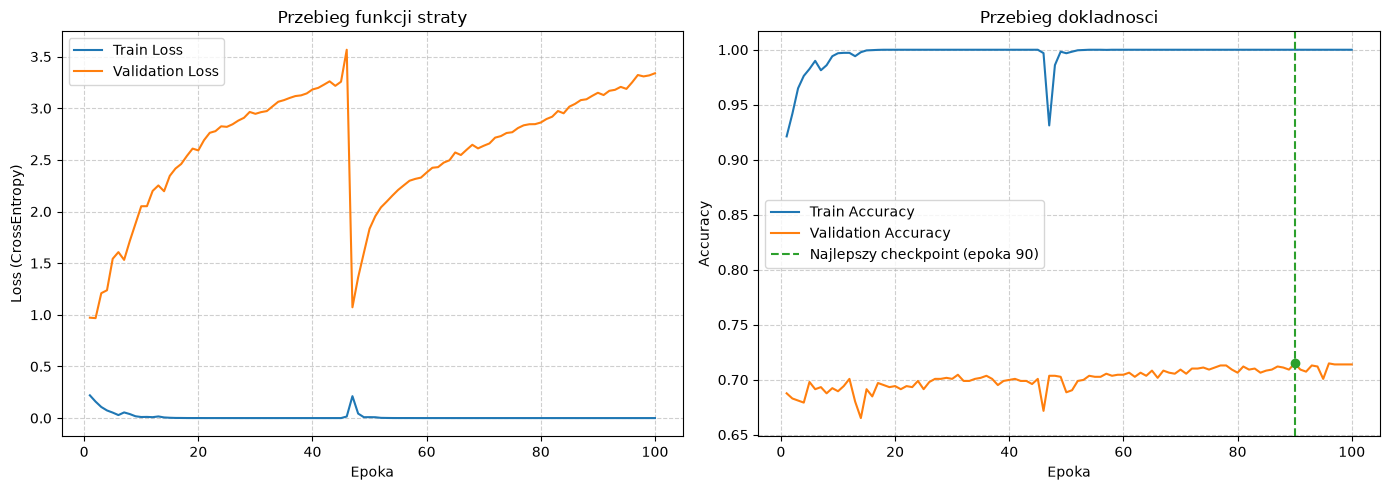

In [11]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Train Loss", color="tab:blue")
plt.plot(epochs, history["val_loss"], label="Validation Loss", color="tab:orange")
plt.xlabel("Epoka")
plt.ylabel("Loss (CrossEntropy)")
plt.title("Przebieg funkcji straty")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_acc"], label="Train Accuracy", color="tab:blue")
plt.plot(epochs, history["val_acc"], label="Validation Accuracy", color="tab:orange")
best_epoch = int(np.argmax(history["val_acc"]) + 1)
best_val = max(history["val_acc"])
plt.axvline(x=best_epoch, color="tab:green", linestyle="--", label=f"Najlepszy checkpoint (epoka {best_epoch})")
plt.scatter([best_epoch], [best_val], color="tab:green", zorder=5)
plt.xlabel("Epoka")
plt.ylabel("Accuracy")
plt.title("Przebieg dokladnosci")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

**Komentarz do przebiegu uczenia:**
Wykres prezentuje proces uczenia przez 100 epok. Strata na zbiorze treningowym (Train Loss) szybko spada do wartosci bliskich zeru, a dokladnosc treningowa (Train Accuracy) osiaga 100%, co oznacza pelne zapamietanie sekwencji treningowych przez siec. Z kolei na zbiorze walidacyjnym strata (Validation Loss) po poczatkowym spadku zaczyna rosnac po okolo 10. epoce, co jest klasycznym objawem przeuczenia (overfitting). Mimo wzrostu wartosci straty, dokladnosc walidacyjna (Validation Accuracy) utrzymuje sie na stabilnym poziomie, osiagajac globalne maksimum rowne 71.48% w 90. epoce. Mechanizm zapisu checkpointu pozwolil zachowac stan modelu z tego optymalnego punktu walidacyjnego, zabezpieczajac przed uzyciem przeuczonych wag z konca treningu.

### 4.2 Wczytanie najlepszego checkpointu i ewaluacja na zbiorze testowym

In [12]:
best_checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

test_loss, test_acc = evaluate(model, test_loader, criterion, device)

print(f"Najlepszy checkpoint z epoki: {best_checkpoint['epoch']}")
print(f"Walidacyjne accuracy checkpointu: {best_checkpoint['val_acc']:.4f}")
print(f"Walidacyjny loss checkpointu: {best_checkpoint['val_loss']:.4f}")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Najlepszy checkpoint z epoki: 90
Walidacyjne accuracy checkpointu: 0.7148
Walidacyjny loss checkpointu: 3.1499
Test Loss: 3.0603
Test Accuracy: 0.7242


### 4.3 Analiza wyników i propozycje usprawnień

**Analiza wyników:**
Model bazowy osiagnal na niezaleznym zbiorze testowym dokladnosc 72.42% (oraz strate testowa 3.0603). Wynik ten jest bardzo zblizony do najwyzszej dokladnosci uzyskanej na zbiorze walidacyjnym (71.48% w 90. epoce), co potwierdza prawidlowosc doboru hiperparametrow i checkpointingu bez wycieku informacji z podzialu testowego. Uzyskana dokladnosc zdecydowanie przewyzsza poziom klasyfikacji losowej (50%), jednak wyrazny wzrost straty walidacyjnej w trakcie treningu oraz spadek dynamiki poprawy jakosci wskazuja na naturalne bariery prostej architektury rekurencyjnej: podatnosc na zjawisko zanikajacego gradientu (ang. vanishing gradient) przy dluzszych wypowiedziach oraz brak mechanizmw selektywnego zapamietywania kluczowych slow nacechowanych emocjonalnie.

**Zasugerowane modyfikacje mogace poprawic jakosc klasyfikacji:**
1. **Zastosowanie sieci dwukierunkowej:** Przetwarzanie sekwencji w obu kierunkach jednoczesnie pozwala na skojarzenie reprezentacji kazdego tokenu z kontekstem wystepujacym zarowno przed nim, jak i po nim, co ma istotne znaczenie w klasyfikacji calych recenzji.
2. **Silniejsza regularyzacja i Early Stopping:** Wdrozenie wczesnego zatrzymywania uczenia (early stopping) z cierpliwoscia np. 10 epok zatrzymaloby trening przed silnym przeuczeniem, a zwiekszenie dropoutu lub dodanie regularyzacji wagowej L2 (weight decay) ograniczyloby nadmierny wzrost wag.
3. **Mechanizm uwagi (Attention) lub architektura Transformer:** Dodanie atencji umozliwia bezposrednie wazenie istotnosci poszczegolnych przymiotnikow i zwrotow w recenzji niezaleznie od ich odleglosci od konca zdania, co eliminuje koniecznosc kondensowania calej tresci tekstu do jednego wektora stanu koncowego.

## Wykorzystanie AI

- **Narzędzie**: Antigravity
- **Model**: Gemini 3.8 Flash (High)
- **Zakres wkładu**:
  - Konfiguracja szablonu: Zebranie wszystkich wymaganych importów bibliotek oraz powtarzalnego ustawienia ziarna losowości (seed=42 dla PyTorch, NumPy i random) w pierwszym punkcie notebooka przed wczytaniem danych.
  - Część 1: Pobranie zbioru Rotten Tomatoes, deterministyczna tokenizacja i normalizacja tekstu, budowa słownika z tokenami specjalnymi (<pad> oraz <unk>) wyłącznie na zbiorze treningowym, implementacja klasy RottenTomatoesDataset, funkcji collate_fn wyrównującej długości sekwencji w batchu (padding) oraz utworzenie obiektów DataLoader dla zbiorów treningowego, walidacyjnego i testowego.
  - Część 2: Implementacja modułu RNNClassifier w PyTorch z warstwą nn.Embedding (padding_idx=0), rekurencyjną nn.RNN z obsługą pack_padded_sequence dla zmiennych długości tekstów, warstwą dropout oraz liniową głowicą klasyfikującą (nn.Linear), a także weryfikacja liczby parametrów i poprawnego przejścia w przód na przykładowym batchu.
  - Część 3: Implementacja funkcji train_epoch oraz evaluate z optymalizatorem Adam i funkcją straty CrossEntropyLoss, pętli treningowej rejestrującej wartości loss i accuracy po każdej epoce na zbiorze treningowym i walidacyjnym oraz mechanizmu zapisu najlepszego checkpointu (best_checkpoint.pt) według najwyższego accuracy walidacyjnego.
  - Część 4: Zwizualizowanie przebiegu funkcji straty i dokładności (loss i accuracy) na zbiorze treningowym i walidacyjnym po 100 epokach wraz z komentarzem do zjawiska przeuczenia, wczytanie najlepszego zapisanego checkpointu (z 90. epoki) i zewaluowanie go na zbiorze testowym (Test Accuracy: 72.42%), a także sporządzenie szczegółowej analizy uzyskanych wyników oraz propozycji usprawnień architektonicznych i regularyzacyjnych.

### Wykorzystane prompty

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
/zajecia-nlp https://christop.faculty.wmi.amu.edu.pl/index.php?page=chapter&id=uczenie-glebokie-w-przetwarzaniu-tekstu&topic=architektury-neuronowe
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
Architektura: RNN (prosta sieć rekurencyjna). Zakres: Krok po kroku: najpierw przygotowanie tekstu, słownik i DataLoader.
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
Ustaw template tak aby wszystkie importy oraz ustawianie seeda byly w pierwszym punkcie
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
ok zdefiniuj teraz model RNN w pytorch
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
przygotuj petle trenignowa wraz z ewaluacja oraz checkpointami
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
przedstaw wykres przebiegu loss i acc oraz wczytaj najlepszy checkpoint i zeewaluuj go na zbiorze testowym i pokaz wyniki
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
przetrenowalem model na 100 epokach, przedstaw wykres przebiegu loss i acc oraz wczytaj najlepszy checkpoint i zeewaluuj go na zbiorze testowym i pokaz wyniki
```
